# Avance 5. Modelo final

**TC5035 Proyecto Integrador · Equipo 56**

Sistema Inteligente para la Optimización de Operaciones de Transporte mediante Inteligencia Artificial aplicada al Análisis Predictivo de Datos GPS (Feraltar).

| Integrante | Matrícula |
|---|---|
| Alejandra Guadalupe Larrañaga Altamirano | A01794334 |
| Mario Alberto Guillén | A01796701 |
| Andrea Kimberly Fray Tamayo | A01797168 |

**Objetivo de este avance:** construir modelos de ensamble, homogéneos y heterogéneos, para predecir la duración del viaje (`duration_seconds`); compararlos contra el mejor modelo individual del Avance 4; elegir el modelo final según las necesidades de operación, y analizar sus predicciones sobre datos no vistos.

**Punto de partida (Avance 4).** El mejor modelo individual fue la red neuronal MLP ajustada, con un MAE de 3.51 min en prueba (55.7 % menos que el baseline de 7.93 min) y 95.7 % de viajes dentro de ±10 min. KNN ajustado quedó prácticamente empatado (3.49 min), pero se descartó por su costo de predicción y memoria. El árbol de decisión quedó a solo 0.4 min, lo que sugiere que combinar muchos árboles puede superar a los modelos individuales.

**Contenido**
1. Retroalimentación del Avance 3
2. Configuración
3. Carga de la partición del Avance 2
4. Protocolo de evaluación
5. Referencias: baseline y mejores modelos individuales
6. Ensambles homogéneos
7. Ensambles heterogéneos
8. Tabla comparativa
9. Modelo final
10. Análisis del modelo final
11. Conclusiones
12. Bibliografía
13. Declaración sobre el uso de herramientas de inteligencia artificial

## 1. Retroalimentación del Avance 3

> *"¿Buscaron la opción de descargar datos de duración de los viajes desde aplicaciones como Google Maps o Waze? (...) La duración cambiaría no solo por la hora de consulta, sino también por las condiciones climatológicas. ¿Llegaron a considerar fuentes exógenas como el clima para estimar sus tiempos?"*

Gracias por el comentario. Hasta ahora los modelos usan distancia, zonas de origen y destino, hora y día de la semana; **no incluyen variables de tráfico externo ni de clima**. Revisamos las dos fuentes que sugiere:

**Tráfico (Google Maps).** La Routes API de Google devuelve la duración estimada de una ruta con tráfico para un origen, un destino y una hora de salida. La podemos usar de dos formas:

1. **Como referencia externa:** comparar nuestro ETA contra el de Google para los mismos viajes. Si nuestro modelo se acerca o lo supera en las rutas de Feraltar, eso valida el modelo; si queda lejos, nos dice dónde falta información.
2. **Como característica:** guardar la duración que estima Google al momento de reservar y usarla como variable de entrada. El modelo aprendería a corregir a Google con lo que sabemos de la operación (tiempos de abordaje, esperas en hoteles, zonas difíciles).

Para Waze no encontramos una API pública para consultar tiempos de ruta; su programa de datos está orientado a gobiernos y ciudades.

**Clima.** Open-Meteo ofrece clima histórico por hora (precipitación, viento, temperatura) sin costo y sin llave de API. En Cancún es especialmente relevante: las lluvias fuertes inundan calles y la temporada de huracanes va de junio a noviembre. Se puede unir a cada viaje por fecha, hora y zona.

**Por qué no lo incorporamos todavía.** Los datos actuales cubren cinco semanas (25 de septiembre a 2 de noviembre), así que casi no hay variación de clima para que el modelo aprenda de ella. Además, la Routes API se cobra por consulta una vez agotado el crédito gratuito.

**Plan.** Hacer justo el ejercicio que propone: un script que consulte cada hora la duración de aeropuerto a cada una de las 27 zonas, junto con el clima del momento. Con unas semanas de consultas tendríamos una serie externa para (a) medir cuánto cambia la duración por hora y por lluvia, y (b) agregarla como característica cuando entrenemos con los viajes reales del piloto GPS. En la sección 10.6 de este avance ya analizamos cómo cambia el error del modelo según la hora del día.

## 2. Configuración

In [4]:
import pickle
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)

SEMILLA = 42
OBJETIVO = "duration_seconds"
COLUMNA_DISTANCIA = "distance_km"

np.random.seed(SEMILLA)

## 3. Carga de la partición del Avance 2

Se usa la misma partición de entrenamiento y prueba de los avances 3 y 4, para que los ensambles se comparen sobre exactamente los mismos viajes que los modelos individuales.

In [6]:
def encontrar_raiz(inicio: Path) -> Path:
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "data" / "processed").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la carpeta data/processed en el repositorio.")


RAIZ = encontrar_raiz(Path.cwd())
PROCESADOS = RAIZ / "data" / "processed"
SUFIJO = "avance2.csv.gz"


def leer_y(nombre: str) -> pd.Series:
    datos = pd.read_csv(PROCESADOS / nombre)
    assert datos.shape[1] == 1, f"{nombre} debería tener una sola columna y tiene {datos.shape[1]}"
    return datos.iloc[:, 0]


X_train = pd.read_csv(PROCESADOS / f"X_train_{SUFIJO}")
X_test = pd.read_csv(PROCESADOS / f"X_test_{SUFIJO}")
y_train = leer_y(f"y_train_{SUFIJO}")
y_test = leer_y(f"y_test_{SUFIJO}")

assert y_train.name == OBJETIVO
assert list(X_train.columns) == list(X_test.columns)

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Características: {X_train.shape[1]}")

X_train: (349445, 59) | X_test: (87362, 59)
Características: 59


## 4. Protocolo de evaluación

Se usa la misma función `registrar` del Avance 4, con las mismas métricas: **MAE en minutos (métrica principal)**, RMSE, R², % de viajes dentro de ±10 y ±15 min, brecha de MAE entre prueba y entrenamiento, y tiempos de entrenamiento y predicción.

El único cambio es que ahora también guarda el modelo entrenado y sus predicciones de prueba, para hacer los gráficos de la sección 10 sin volver a entrenar.

In [8]:
resultados = []
modelos = {}        # nombre -> modelo entrenado
predicciones = {}   # nombre -> predicciones sobre X_test (segundos)


def registrar(nombre, modelo, n_entrenamiento=None, columnas=None):
    """Entrena, mide tiempos y guarda las métricas, el modelo y sus predicciones.

    nombre:          nombre del modelo en la tabla comparativa.
    modelo:          estimador de scikit-learn (o Pipeline) sin entrenar.
    n_entrenamiento: si se indica, entrena con una muestra aleatoria de ese tamaño.
    columnas:        si se indica, usa solo esas columnas (por defecto, las 59).
    """
    X_tr, y_tr = X_train, y_train
    if n_entrenamiento is not None and n_entrenamiento < len(X_train):
        idx = X_train.sample(n_entrenamiento, random_state=SEMILLA).index
        X_tr, y_tr = X_train.loc[idx], y_train.loc[idx]
    X_te = X_test
    if columnas is not None:
        X_tr, X_te = X_tr[columnas], X_te[columnas]

    inicio = time.perf_counter()
    modelo.fit(X_tr, y_tr)
    t_entrenamiento = time.perf_counter() - inicio

    inicio = time.perf_counter()
    pred_test = modelo.predict(X_te)
    t_prediccion = time.perf_counter() - inicio
    pred_train = modelo.predict(X_tr)

    error_test = np.abs(y_test.values - pred_test) / 60
    fila = {
        "modelo": nombre,
        "MAE_min": error_test.mean(),
        "RMSE_min": np.sqrt(mean_squared_error(y_test, pred_test)) / 60,
        "R2": r2_score(y_test, pred_test),
        "dentro_10min_%": (error_test <= 10).mean() * 100,
        "dentro_15min_%": (error_test <= 15).mean() * 100,
        "MAE_train_min": mean_absolute_error(y_tr, pred_train) / 60,
        "t_entrenamiento_s": t_entrenamiento,
        "t_prediccion_s": t_prediccion,
        "n_entrenamiento": len(X_tr),
    }
    fila["brecha_MAE_min"] = fila["MAE_min"] - fila["MAE_train_min"]

    resultados[:] = [r for r in resultados if r["modelo"] != nombre]
    resultados.append(fila)
    modelos[nombre] = modelo
    predicciones[nombre] = pred_test
    return pd.Series(fila).drop("modelo").round(3)

## 5. Referencias: baseline y mejores modelos individuales

Se vuelven a entrenar, con los hiperparámetros elegidos en avances anteriores, el baseline del Avance 3 y los tres mejores modelos individuales del Avance 4. Los tres individuales se usan después como modelos base de los ensambles heterogéneos (sección 7), como pide la actividad.

| Modelo | Hiperparámetros | Origen |
|---|---|---|
| Lasso (baseline) | `alpha=0.001` | Avance 3, validación cruzada |
| MLP ajustada | capas (64, 32), ReLU, `alpha=1e-5`, tasa `3e-3`, lote 512 | Avance 4, `RandomizedSearchCV` |
| KNN ajustado | 5 vecinos, pesos por distancia, euclidiana | Avance 4, `GridSearchCV` |
| Árbol de decisión | `max_depth=16`, `min_samples_leaf=15` | Avance 4 |

In [10]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor


def crear_mlp_ajustada():
    red = MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-5,
                       learning_rate_init=3e-3, batch_size=512, early_stopping=True,
                       max_iter=200, random_state=SEMILLA)
    # El objetivo está en segundos; la red converge mejor si se estandariza
    return TransformedTargetRegressor(regressor=red, transformer=StandardScaler())


def crear_knn_ajustado():
    return KNeighborsRegressor(n_neighbors=5, weights="distance", p=2)


def crear_arbol():
    return DecisionTreeRegressor(max_depth=16, min_samples_leaf=15, random_state=SEMILLA)


registrar("Ref. Lasso (baseline Avance 3)", Lasso(alpha=0.001, max_iter=2000, tol=1e-3))
registrar("MLP ajustada (Avance 4)", crear_mlp_ajustada())
registrar("KNN ajustado (Avance 4)", crear_knn_ajustado())
registrar("Árbol de decisión (Avance 4)", crear_arbol())

pd.DataFrame(resultados).set_index("modelo")[
    ["MAE_min", "RMSE_min", "dentro_10min_%", "brecha_MAE_min", "t_entrenamiento_s"]
].round(3)

,MAE_min,RMSE_min,dentro_10min_%,brecha_MAE_min,t_entrenamiento_s
modelo,,,,,
Ref. Lasso (baseline Avance 3),7.934,10.273,70.298,-0.030,4.671
MLP ajustada (Avance 4),3.513,4.626,95.703,1.014,25.380
KNN ajustado (Avance 4),3.493,4.698,95.178,1.312,0.047
Árbol de decisión (Avance 4),3.903,5.202,93.333,0.871,0.806


Los resultados coinciden con los del Avance 4: MLP ajustada 3.51 min, KNN ajustado 3.49 min y árbol 3.90 min. La semilla fija hace que se reproduzcan igual, así que los ensambles se comparan contra los mismos números.

## 6. Ensambles homogéneos

Combinan muchos modelos **del mismo tipo** (aquí, árboles de decisión) entrenados de forma distinta:

| # | Ensamble | Estrategia | Idea |
|---|---|---|---|
| 6.1 | Random Forest | Bagging | Cada árbol se entrena con una muestra distinta de viajes y de variables; promediar reduce la varianza del árbol individual |
| 6.2 | Extra Trees | Bagging con cortes aleatorios | Como Random Forest, pero elige los cortes al azar; más rápido y con aún menos varianza |
| 6.3 | Gradient Boosting (histogramas) | Boosting | Cada árbol nuevo corrige los errores de los anteriores; reduce el sesgo |
| 6.4 | Gradient Boosting ajustado | Boosting | El mismo, con búsqueda de hiperparámetros |

Se usa `HistGradientBoostingRegressor` de scikit-learn en lugar de `GradientBoostingRegressor` porque agrupa cada variable en histogramas y entrena decenas de veces más rápido con 350 mil viajes, con un desempeño equivalente al de XGBoost o LightGBM, sin agregar dependencias al proyecto.

### 6.1 Random Forest

100 árboles con profundidad máxima 18 y al menos 10 viajes por hoja. Cada árbol usa la mitad de los viajes (`max_samples=0.5`) y, en cada corte, la mitad de las variables (`max_features=0.5`). Esos límites mantienen el modelo en un tamaño manejable: sin ellos, 100 árboles completos sobre 350 mil viajes ocuparían varios GB de memoria.

In [14]:
from sklearn.ensemble import RandomForestRegressor

registrar("Random Forest", RandomForestRegressor(
    n_estimators=100, max_depth=18, min_samples_leaf=10,
    max_features=0.5, max_samples=0.5, n_jobs=-1, random_state=SEMILLA,
))

MAE_min               3.616609
RMSE_min              4.783065
R2                    0.995972
dentro_10min_%       95.153499
dentro_15min_%       99.538701
MAE_train_min         2.927757
t_entrenamiento_s     2.795136
t_prediccion_s        0.079374
n_entrenamiento         349445
brecha_MAE_min        0.688852
dtype: object

> **Por escribir:** MAE contra la MLP ajustada y contra el árbol individual (¿cuánto mejoró promediar 100 árboles?), brecha de sobreajuste y tiempo de entrenamiento.

### 6.2 Extra Trees

Mismos límites que Random Forest para que la comparación sea justa. La diferencia es que en cada corte prueba umbrales al azar en lugar de buscar el mejor.

In [17]:
from sklearn.ensemble import ExtraTreesRegressor

registrar("Extra Trees", ExtraTreesRegressor(
    n_estimators=100, max_depth=18, min_samples_leaf=10,
    max_features=0.5, bootstrap=True, max_samples=0.5, n_jobs=-1, random_state=SEMILLA,
))

MAE_min               4.231483
RMSE_min              5.590251
R2                    0.994498
dentro_10min_%        92.25178
dentro_15min_%       98.183421
MAE_train_min         4.166201
t_entrenamiento_s     2.396957
t_prediccion_s        0.064591
n_entrenamiento         349445
brecha_MAE_min        0.065282
dtype: object

> **Por escribir:** comparación contra Random Forest en error y en tiempo de entrenamiento.

### 6.3 Gradient Boosting (hiperparámetros por defecto)

Primero con los valores por defecto, para medir después cuánto aporta el ajuste. Usa `early_stopping`: aparta 10 % del entrenamiento y deja de agregar árboles cuando el error de validación deja de bajar.

In [20]:
from sklearn.ensemble import HistGradientBoostingRegressor

registrar("Gradient Boosting (por defecto)", HistGradientBoostingRegressor(random_state=SEMILLA))

MAE_min               3.699427
RMSE_min              4.800647
R2                    0.995943
dentro_10min_%       95.317186
dentro_15min_%       99.706966
MAE_train_min          2.97162
t_entrenamiento_s     2.922814
t_prediccion_s        0.077639
n_entrenamiento         349445
brecha_MAE_min        0.727807
dtype: object

### 6.4 Gradient Boosting ajustado

Se sigue el mismo procedimiento del Avance 4: `RandomizedSearchCV` con 20 combinaciones, validación cruzada de 3 particiones sobre una muestra de 50 mil viajes, y la mejor configuración se reentrena con los 349,445 viajes. Se exploran:

- **`learning_rate`:** cuánto corrige cada árbol. Tasas bajas necesitan más árboles pero suelen generalizar mejor.
- **`max_iter`:** número máximo de árboles (el `early_stopping` puede detenerse antes).
- **`max_leaf_nodes`:** complejidad de cada árbol.
- **`min_samples_leaf`:** mínimo de viajes por hoja; evita reglas basadas en pocos viajes.
- **`l2_regularization`:** penaliza hojas con valores extremos.

In [22]:
from sklearn.base import clone
from sklearn.model_selection import KFold, RandomizedSearchCV

# La búsqueda se hace sobre 50 mil viajes para que sea rápida; el mejor modelo se reentrena con todos
idx = X_train.sample(50_000, random_state=SEMILLA).index
X_bus, y_bus = X_train.loc[idx], y_train.loc[idx]
kfold = KFold(n_splits=3, shuffle=True, random_state=SEMILLA)


def resumen_busqueda(busqueda, top=10):
    """Tabla de configuraciones probadas, ordenada por MAE de validación cruzada en minutos."""
    r = pd.DataFrame(busqueda.cv_results_)
    r["MAE_cv_min"] = -r["mean_test_score"] / 60
    r["desv_cv_min"] = r["std_test_score"] / 60
    columnas = [c for c in r.columns if c.startswith("param_")] + ["MAE_cv_min", "desv_cv_min", "mean_fit_time"]
    return r[columnas].sort_values("MAE_cv_min").head(top).round(3)


espacio_gb = {
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
    "max_iter": [200, 400, 800],
    "max_leaf_nodes": [15, 31, 63, 127],
    "min_samples_leaf": [10, 20, 50, 100],
    "l2_regularization": [0.0, 0.1, 1.0],
}
busqueda_gb = RandomizedSearchCV(HistGradientBoostingRegressor(random_state=SEMILLA), espacio_gb,
                                 n_iter=20, cv=kfold, scoring="neg_mean_absolute_error",
                                 n_jobs=-1, random_state=SEMILLA)
inicio = time.perf_counter()
busqueda_gb.fit(X_bus, y_bus)
print(f"Tiempo de búsqueda: {time.perf_counter() - inicio:.0f} s")
print("Mejores hiperparámetros:", busqueda_gb.best_params_)

gb_ajustado = clone(busqueda_gb.best_estimator_)
registrar("Gradient Boosting ajustado", gb_ajustado)
print("Árboles usados tras early stopping:", gb_ajustado.n_iter_)
resumen_busqueda(busqueda_gb)

Tiempo de búsqueda: 42 s
Mejores hiperparámetros: {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 800, 'learning_rate': 0.05, 'l2_regularization': 0.1}
Árboles usados tras early stopping: 680


,param_min_samples_leaf,param_max_leaf_nodes,param_max_iter,param_learning_rate,param_l2_regularization,MAE_cv_min,desv_cv_min,mean_fit_time
12,20,63,800,0.05,0.1,2.485,0.012,8.312
15,100,31,400,0.20,0.0,2.491,0.011,5.128
0,50,63,800,0.03,0.1,2.491,0.012,15.132
16,20,63,400,0.05,0.1,2.497,0.002,7.124
2,50,63,200,0.20,0.1,2.507,0.010,3.284
10,50,31,800,0.05,1.0,2.508,0.013,10.887
7,20,127,400,0.03,0.0,2.510,0.007,11.821
1,50,31,400,0.10,0.0,2.522,0.019,5.288
19,20,63,200,0.20,0.0,2.524,0.004,2.372
18,10,127,800,0.10,1.0,2.531,0.005,3.400


In [23]:
# Antes contra después del ajuste
pd.DataFrame(resultados).set_index("modelo").loc[
    ["Gradient Boosting (por defecto)", "Gradient Boosting ajustado"],
    ["MAE_min", "RMSE_min", "dentro_10min_%", "brecha_MAE_min", "t_entrenamiento_s"],
].round(3)

,MAE_min,RMSE_min,dentro_10min_%,brecha_MAE_min,t_entrenamiento_s
modelo,,,,,
Gradient Boosting (por defecto),3.699,4.801,95.317,0.728,2.923
Gradient Boosting ajustado,3.432,4.577,95.742,1.113,19.142


> **Por escribir:** qué hiperparámetros ganaron, cuánto bajó el MAE respecto a la versión por defecto y si alguno quedó en el borde del espacio de búsqueda (como pasó con la MLP en el Avance 4).

## 7. Ensambles heterogéneos

Combinan modelos **de tipos distintos**. Como pide la actividad, se usan los tres mejores modelos individuales del Avance 4: la MLP ajustada, KNN ajustado y el árbol de decisión. La idea es que se equivocan de forma distinta (la red aprende una función suave, KNN copia viajes parecidos y el árbol hace cortes por regiones), así que al combinarlos los errores se compensan.

| # | Ensamble | Cómo combina |
|---|---|---|
| 7.1 | Voting | Promedia las predicciones de los tres modelos, con el mismo peso |
| 7.2 | Stacking | Un metamodelo (Ridge) aprende cuánto peso darle a cada uno |

### 7.1 Voting

Cada modelo se entrena con los 349,445 viajes y la predicción final es el promedio de los tres.

In [27]:
from sklearn.ensemble import VotingRegressor

base_heterogenea = [
    ("mlp", crear_mlp_ajustada()),
    ("knn", crear_knn_ajustado()),
    ("arbol", crear_arbol()),
]
registrar("Voting (MLP + KNN + árbol)", VotingRegressor(base_heterogenea))

MAE_min               3.465149
RMSE_min              4.613597
R2                    0.996253
dentro_10min_%       95.578169
dentro_15min_%       99.774501
MAE_train_min         2.384587
t_entrenamiento_s    21.262626
t_prediccion_s       12.560689
n_entrenamiento         349445
brecha_MAE_min        1.080562
dtype: object

El voting bajó el MAE a 3.47 min: 0.03 min menos que KNN, el mejor de los tres solo (3.49), y 0.05 menos que la MLP (3.51). También mejoró el RMSE (4.61 contra 4.63 de la MLP), así que promediar sí compensa algunos errores de cada modelo.

La mejora es pequeña porque los tres modelos se equivocan en los mismos viajes casi siempre, y el árbol, que es el más débil (3.90 min), pesa lo mismo que los otros dos. El costo está en la predicción: tarda 12.6 s en el conjunto de prueba porque arrastra la lentitud de KNN.

### 7.2 Stacking

En lugar de pesos iguales, un metamodelo aprende la mejor combinación:

1. Con validación cruzada de 3 particiones se obtienen predicciones de cada modelo base sobre viajes que **no vio al entrenar**.
2. Con esas predicciones se entrena el metamodelo, una regresión Ridge con `alpha` elegido por validación cruzada (`RidgeCV`). Se usa un metamodelo lineal porque solo tiene que repartir pesos entre tres predicciones muy parecidas; uno más complejo tendería a sobreajustar.
3. Los modelos base se reentrenan con todos los viajes para predecir.

Es el ensamble más lento de entrenar (cada modelo base se entrena 4 veces).

In [30]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV

stacking = StackingRegressor(
    estimators=base_heterogenea,
    final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 13)),
    cv=kfold, n_jobs=1,
)
registrar("Stacking (MLP + KNN + árbol → Ridge)", stacking)

pesos = pd.Series(stacking.final_estimator_.coef_, index=[n for n, _ in base_heterogenea], name="peso")
print("Pesos que aprendió el metamodelo:")
pesos.round(3)

Pesos que aprendió el metamodelo:


mlp      0.913
knn     -0.091
arbol    0.178
Name: peso, dtype: float64

El metamodelo le dio casi todo el peso a la MLP (0.91), un poco al árbol (0.18) y un peso negativo a KNN (-0.09). El peso negativo no quiere decir que KNN sea malo: las tres predicciones son casi iguales, y Ridge usa a KNN como una pequeña corrección sobre lo que ya dicen la MLP y el árbol.

En MAE el stacking (3.51 min) no superó al voting (3.47) y quedó igual que la MLP sola. Tiene sentido, porque Ridge minimiza el error cuadrático, no el absoluto: optimiza para evitar errores grandes. Por eso tiene el mayor porcentaje de viajes dentro de ±10 min (95.74 %) y dentro de ±15 min (99.87 %) de toda la tabla. Es también el más lento de entrenar (80 s), porque entrena cada modelo base cuatro veces.

## 8. Tabla comparativa

Todos los modelos ordenados por la métrica principal (MAE en prueba). Se incluyen el baseline y los individuales del Avance 4 como referencia.

In [33]:
columnas_tabla = ["MAE_min", "RMSE_min", "R2", "dentro_10min_%", "dentro_15min_%",
                  "brecha_MAE_min", "t_entrenamiento_s", "t_prediccion_s"]
tipo = {
    "Ref. Lasso (baseline Avance 3)": "Referencia",
    "MLP ajustada (Avance 4)": "Individual", "KNN ajustado (Avance 4)": "Individual",
    "Árbol de decisión (Avance 4)": "Individual",
    "Random Forest": "Homogéneo", "Extra Trees": "Homogéneo",
    "Gradient Boosting (por defecto)": "Homogéneo", "Gradient Boosting ajustado": "Homogéneo",
    "Voting (MLP + KNN + árbol)": "Heterogéneo", "Stacking (MLP + KNN + árbol → Ridge)": "Heterogéneo",
}
comparacion = pd.DataFrame(resultados).set_index("modelo")[columnas_tabla].sort_values("MAE_min")
comparacion.insert(0, "tipo", comparacion.index.map(tipo))
baseline = comparacion.loc["Ref. Lasso (baseline Avance 3)", "MAE_min"]
mejor_individual = comparacion.loc["MLP ajustada (Avance 4)", "MAE_min"]
comparacion["mejora_vs_MLP_%"] = (1 - comparacion["MAE_min"] / mejor_individual) * 100
comparacion.round(3)

,tipo,MAE_min,RMSE_min,R2,dentro_10min_%,dentro_15min_%,brecha_MAE_min,t_entrenamiento_s,t_prediccion_s,mejora_vs_MLP_%
modelo,,,,,,,,,,
Gradient Boosting ajustado,Homogéneo,3.432,4.577,0.996,95.742,99.750,1.113,19.142,0.445,2.327
Voting (MLP + KNN + árbol),Heterogéneo,3.465,4.614,0.996,95.578,99.775,1.081,21.263,12.561,1.372
KNN ajustado (Avance 4),Individual,3.493,4.698,0.996,95.178,99.621,1.312,0.047,12.284,0.570
MLP ajustada (Avance 4),Individual,3.513,4.626,0.996,95.703,99.852,1.014,25.380,0.057,0.000
Stacking (MLP + KNN + árbol → Ridge),Heterogéneo,3.514,4.619,0.996,95.744,99.868,0.974,79.792,12.497,-0.016
Random Forest,Homogéneo,3.617,4.783,0.996,95.153,99.539,0.689,2.795,0.079,-2.939
Gradient Boosting (por defecto),Homogéneo,3.699,4.801,0.996,95.317,99.707,0.728,2.923,0.078,-5.296
Árbol de decisión (Avance 4),Individual,3.903,5.202,0.995,93.333,99.043,0.871,0.806,0.013,-11.079
Extra Trees,Homogéneo,4.231,5.590,0.994,92.252,98.183,0.065,2.397,0.065,-20.440


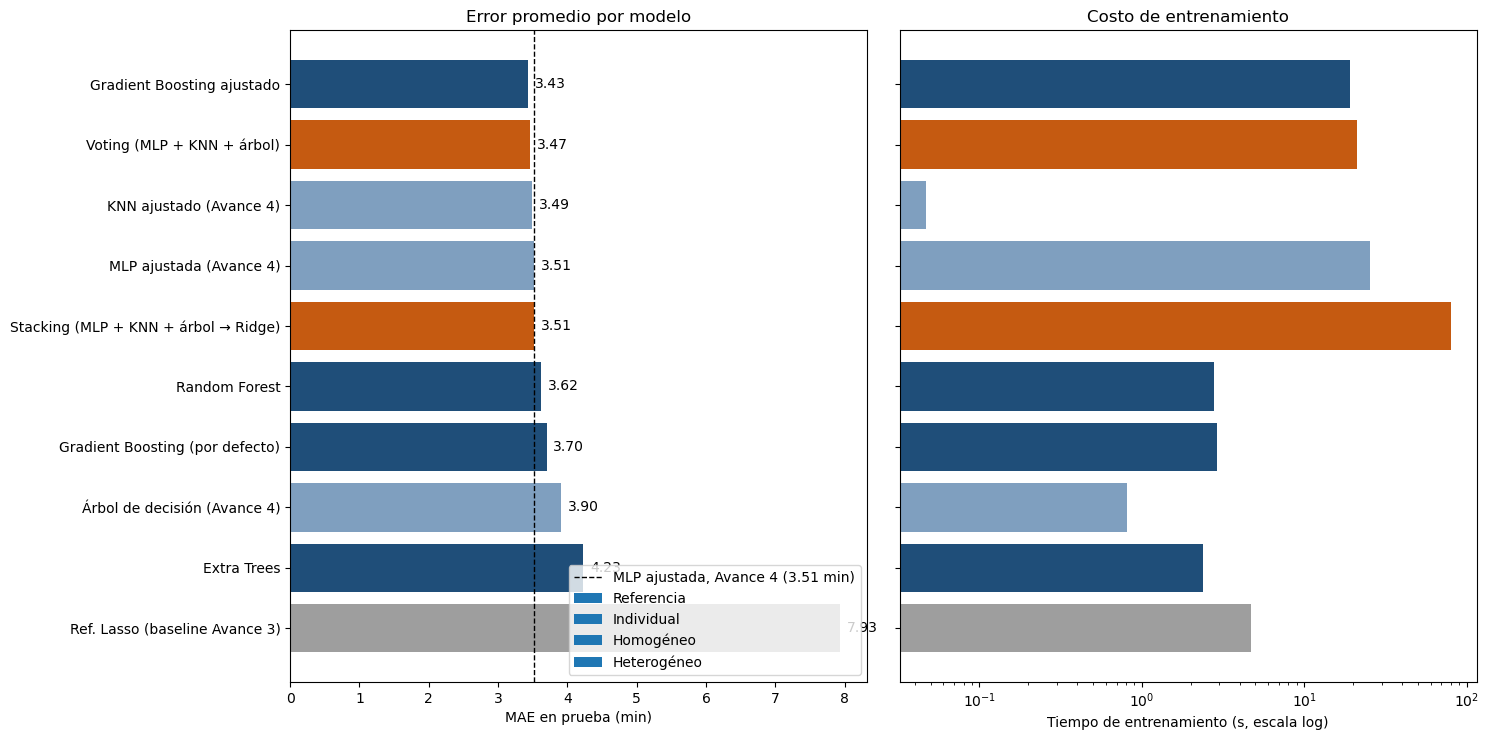

In [34]:
tabla = comparacion.sort_values("MAE_min", ascending=False)
paleta = {"Referencia": "#9e9e9e", "Individual": "#7f9fbf", "Homogéneo": "#1f4e79", "Heterogéneo": "#c55a11"}
colores = tabla["tipo"].map(paleta)

fig, axes = plt.subplots(1, 2, figsize=(15, 0.55 * len(tabla) + 2))

axes[0].barh(tabla.index, tabla["MAE_min"], color=colores)
axes[0].axvline(mejor_individual, color="black", linestyle="--", linewidth=1,
                label=f"MLP ajustada, Avance 4 ({mejor_individual:.2f} min)")
axes[0].set_xlabel("MAE en prueba (min)")
axes[0].set_title("Error promedio por modelo")
for k, v in enumerate(tabla["MAE_min"]):
    axes[0].text(v + 0.1, k, f"{v:.2f}", va="center")
for nombre_tipo, color in paleta.items():
    axes[0].barh([], [], color=color, label=nombre_tipo)
axes[0].legend(loc="lower right")

axes[1].barh(tabla.index, tabla["t_entrenamiento_s"], color=colores)
axes[1].set_xscale("log")
axes[1].set_xlabel("Tiempo de entrenamiento (s, escala log)")
axes[1].set_title("Costo de entrenamiento")
axes[1].set_yticklabels([])

plt.tight_layout()
plt.show()

- **Solo dos ensambles superan a los dos mejores individuales:** Gradient Boosting ajustado (3.43 min) y Voting (3.47 min). El stacking queda empatado con la MLP (3.51).
- **El mejor fue un ensamble homogéneo, el Gradient Boosting ajustado.** Bajó el MAE 2.3 % respecto a la MLP ajustada (0.08 min, unos 5 segundos por viaje) y 56.7 % respecto al baseline. También tiene el menor RMSE de todos (4.58 min).
- **El ajuste fue lo que hizo ganar al boosting:** con los valores por defecto quedaba en 3.70 min, por debajo de la MLP; ajustado bajó a 3.43 (7.2 % menos).
- **Bagging ayudó al árbol, pero no alcanzó a la MLP.** Random Forest bajó el error del árbol de 3.90 a 3.62 min. Extra Trees quedó en 4.23 min, peor que el árbol solo: con cortes al azar y los límites de profundidad le falta capacidad (su MAE de entrenamiento es casi igual al de prueba).
- **La mejora de los ensambles es real pero pequeña.** Los mejores modelos individuales ya habían resuelto el subajuste del Avance 3, y las mejoras de ahora son de segundos por viaje, no de minutos.

## 9. Modelo final

Igual que en el Avance 4, la elección no se basa solo en el MAE. Para los mejores candidatos se mide lo que importa al calcular el ETA en operación: el tiempo de predecir **un solo viaje**, el tamaño del modelo (memoria del servidor) y el tiempo de entrenamiento (el modelo se reentrenará conforme lleguen viajes reales del GPS).

In [37]:
def latencia_ms(modelo, repeticiones=100):
    """Tiempo promedio de predecir un solo viaje, como al calcular un ETA en producción."""
    viaje = X_test.iloc[[0]]
    modelo.predict(viaje)  # calentamiento
    inicio = time.perf_counter()
    for _ in range(repeticiones):
        modelo.predict(viaje)
    return (time.perf_counter() - inicio) / repeticiones * 1000


# Los 3 ensambles con menor MAE, más la MLP ajustada como referencia
ensambles = comparacion[comparacion["tipo"].isin(["Homogéneo", "Heterogéneo"])]
candidatos = list(ensambles.index[:3]) + ["MLP ajustada (Avance 4)"]

tabla_final = comparacion.loc[candidatos, ["tipo", "MAE_min", "RMSE_min", "dentro_10min_%",
                                           "dentro_15min_%", "t_entrenamiento_s"]].copy()
tabla_final["latencia_1_viaje_ms"] = [latencia_ms(modelos[m]) for m in candidatos]
tabla_final["tamaño_modelo_MB"] = [len(pickle.dumps(modelos[m])) / 1e6 for m in candidatos]
tabla_final.round(3)

,tipo,MAE_min,RMSE_min,dentro_10min_%,dentro_15min_%,t_entrenamiento_s,latencia_1_viaje_ms,tamaño_modelo_MB
modelo,,,,,,,,
Gradient Boosting ajustado,Homogéneo,3.432,4.577,95.742,99.750,19.142,18.964,4.876
Voting (MLP + KNN + árbol),Heterogéneo,3.465,4.614,95.578,99.775,21.263,5.040,169.038
Stacking (MLP + KNN + árbol → Ridge),Heterogéneo,3.514,4.619,95.744,99.868,79.792,5.196,169.039
MLP ajustada (Avance 4),Individual,3.513,4.626,95.703,99.852,25.380,0.266,0.150


In [38]:
# Modelo final: por defecto el ensamble con menor MAE.
# Si por los argumentos de negocio eligen otro, escriban aquí su nombre tal como aparece en la tabla.
MODELO_FINAL = ensambles.index[0]

modelo_final = modelos[MODELO_FINAL]
pred_final = predicciones[MODELO_FINAL]
print("Modelo final:", MODELO_FINAL)
comparacion.loc[[MODELO_FINAL]].round(3)

Modelo final: Gradient Boosting ajustado


,tipo,MAE_min,RMSE_min,R2,dentro_10min_%,dentro_15min_%,brecha_MAE_min,t_entrenamiento_s,t_prediccion_s,mejora_vs_MLP_%
modelo,,,,,,,,,,
Gradient Boosting ajustado,Homogéneo,3.432,4.577,0.996,95.742,99.75,1.113,19.142,0.445,2.327


### Elección del modelo final: Gradient Boosting ajustado

| Criterio | Gradient Boosting ajustado | Voting | Stacking | MLP ajustada |
|---|---|---|---|---|
| MAE | **3.43 min** | 3.47 min | 3.51 min | 3.51 min |
| RMSE | **4.58 min** | 4.61 min | 4.62 min | 4.63 min |
| Dentro de ±15 min | 99.75 % | 99.78 % | **99.87 %** | 99.85 % |
| Entrenamiento | 19 s | 21 s | 80 s | 25 s |
| Predicción de un viaje | 19 ms | 5 ms | 5 ms | **0.3 ms** |
| Tamaño del modelo | 4.9 MB | 169 MB | 169 MB | **0.15 MB** |
| Crece con los datos | No | Sí (incluye KNN) | Sí (incluye KNN) | No |

Elegimos el **Gradient Boosting ajustado** por estas razones:

- **Tiene el menor error promedio y el menor RMSE.** Se equivoca menos en promedio y también comete menos errores grandes que el resto.
- **No crece con los datos.** El voting y el stacking incluyen KNN, que guarda los 349 mil viajes (169 MB) y se hace más lento con cada viaje nuevo. El sistema va a acumular viajes GPS todos los días, así que eso los descarta para producción, aunque el stacking tenga el mejor porcentaje dentro de ±15 min por una diferencia mínima.
- **Es fácil de mantener.** Se reentrena en 19 s y pesa 4.9 MB.
- **Se puede interpretar mejor que la MLP.** Al ser de árboles, se puede analizar qué variables pesan más (sección 10.5).
- **Prepara el siguiente paso.** `HistGradientBoostingRegressor` acepta valores faltantes sin tratamiento previo. Eso sirve para agregar las variables de tráfico y clima que propusimos en la sección 1, porque esas consultas externas a veces fallan o no tienen dato para todos los viajes.

**Lo que cedemos.** Frente a la MLP, predice un viaje en 19 ms contra 0.3 ms, porque recorre sus 680 árboles. Para calcular un ETA por reservación, 19 ms siguen siendo inmediatos, y ese tiempo no aumenta conforme se acumulan viajes. A cambio ganamos 0.08 min de MAE (unos 5 segundos por viaje), menos errores grandes y un modelo más fácil de explicar.

## 10. Análisis del modelo final

Seis gráficos sobre el conjunto de prueba (87,362 viajes que el modelo no vio). Los residuos se definen como **duración real menos duración predicha**, en minutos:

- **Residuo positivo:** el viaje tardó más de lo estimado (ETA optimista; el cliente espera o el chofer llega tarde al siguiente servicio).
- **Residuo negativo:** el viaje tardó menos de lo estimado (ETA pesimista; la unidad queda ociosa).

In [41]:
real_min = y_test.values / 60
pred_min = pred_final / 60
residuo = real_min - pred_min
print(f"Residuo promedio: {residuo.mean():+.2f} min | mediana: {np.median(residuo):+.2f} min")
print(f"Viajes con ETA optimista por más de 10 min: {(residuo > 10).mean() * 100:.2f} %")
print(f"Viajes con ETA pesimista por más de 10 min: {(residuo < -10).mean() * 100:.2f} %")

Residuo promedio: -0.11 min | mediana: -0.26 min
Viajes con ETA optimista por más de 10 min: 2.31 %
Viajes con ETA pesimista por más de 10 min: 1.95 %


### 10.1 Duración predicha contra duración real

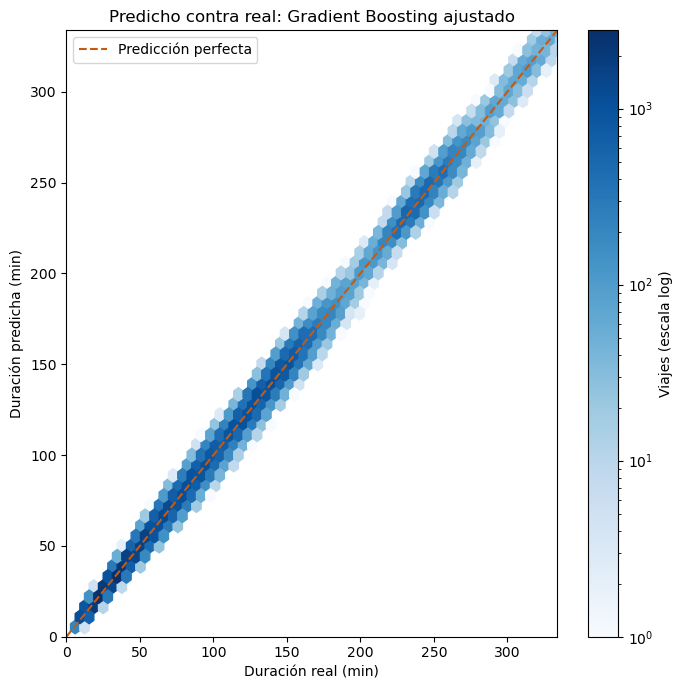

In [43]:
fig, ax = plt.subplots(figsize=(7, 7))
hb = ax.hexbin(real_min, pred_min, gridsize=60, bins="log", cmap="Blues", mincnt=1)
limite = [0, np.percentile(real_min, 99.5)]
ax.plot(limite, limite, color="#c55a11", linestyle="--", label="Predicción perfecta")
ax.set_xlim(limite)
ax.set_ylim(limite)
ax.set_xlabel("Duración real (min)")
ax.set_ylabel("Duración predicha (min)")
ax.set_title(f"Predicho contra real: {MODELO_FINAL}")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="Viajes (escala log)")
plt.tight_layout()
plt.show()

> **Por escribir:** ¿los puntos se concentran sobre la diagonal en todo el rango de duraciones, o se abren en los viajes largos?

### 10.2 Residuos contra duración predicha

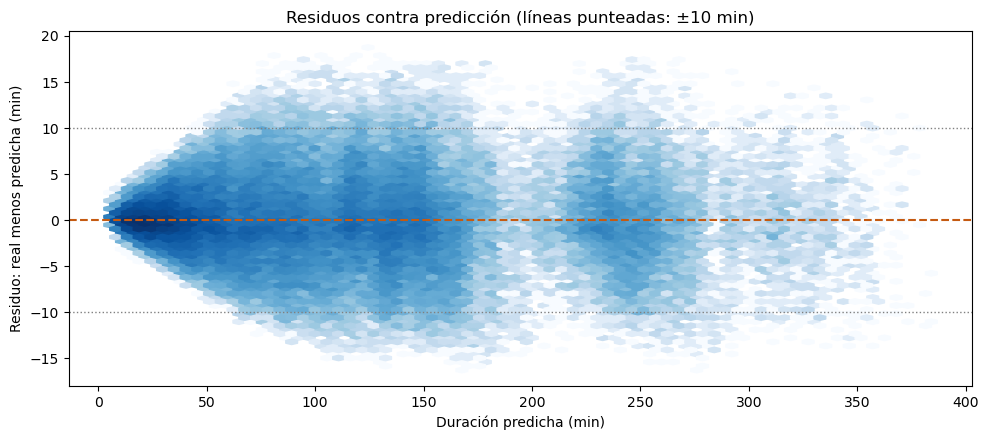

In [46]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hexbin(pred_min, residuo, gridsize=70, bins="log", cmap="Blues", mincnt=1)
ax.axhline(0, color="#c55a11", linestyle="--")
for banda in (-10, 10):
    ax.axhline(banda, color="gray", linestyle=":", linewidth=1)
ax.set_xlabel("Duración predicha (min)")
ax.set_ylabel("Residuo: real menos predicha (min)")
ax.set_title("Residuos contra predicción (líneas punteadas: ±10 min)")
plt.tight_layout()
plt.show()

> **Por escribir:** ¿los residuos están centrados en 0 sin patrón (bien) o forman una curva o un embudo? En el Avance 3 el baseline mostraba una curva con la distancia; ¿desapareció?

### 10.3 Distribución de los residuos

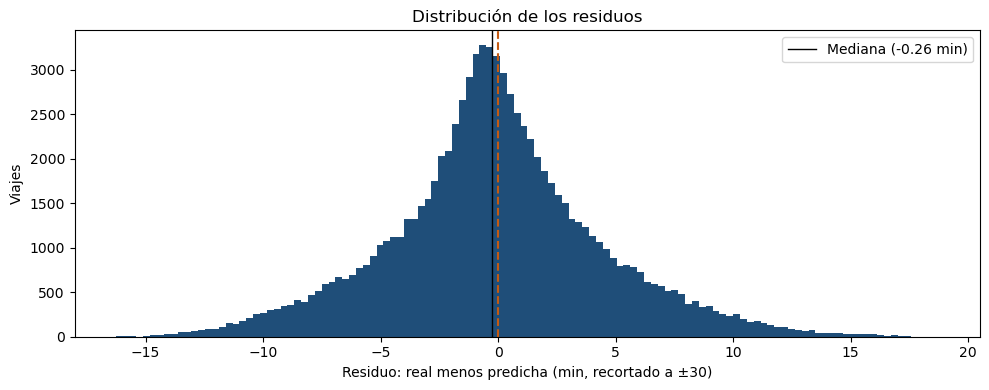

In [49]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(np.clip(residuo, -30, 30), bins=120, color="#1f4e79")
ax.axvline(0, color="#c55a11", linestyle="--")
ax.axvline(np.median(residuo), color="black", linewidth=1, label=f"Mediana ({np.median(residuo):+.2f} min)")
ax.set_xlabel("Residuo: real menos predicha (min, recortado a ±30)")
ax.set_ylabel("Viajes")
ax.set_title("Distribución de los residuos")
ax.legend()
plt.tight_layout()
plt.show()

> **Por escribir:** ¿la distribución es simétrica? Si se carga a la derecha, el modelo tiende a subestimar la duración (ETA optimista), que es el error más costoso para operaciones.

### 10.4 Error por tramo de distancia

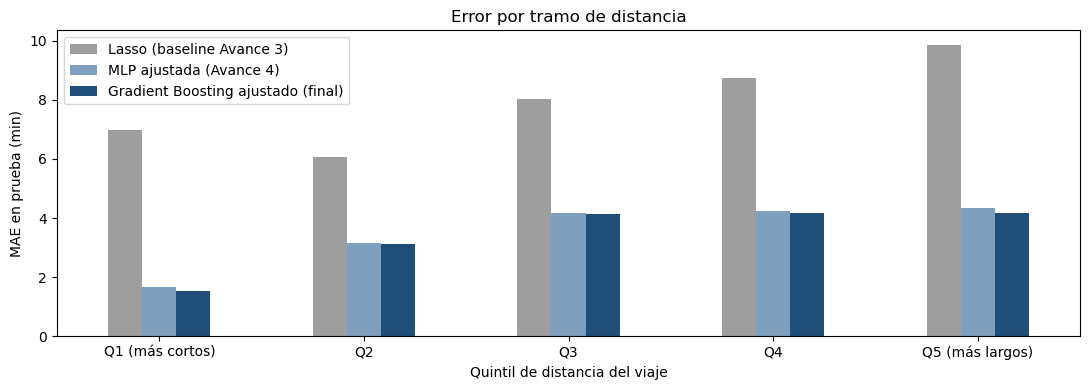

,Lasso (baseline Avance 3),MLP ajustada (Avance 4),Gradient Boosting ajustado (final)
tramo,,,
Q1 (más cortos),6.97,1.67,1.54
Q2,6.07,3.15,3.13
Q3,8.04,4.18,4.15
Q4,8.75,4.24,4.18
Q5 (más largos),9.86,4.32,4.17


In [52]:
tramos = pd.qcut(X_test[COLUMNA_DISTANCIA], q=5,
                 labels=["Q1 (más cortos)", "Q2", "Q3", "Q4", "Q5 (más largos)"])
comparar = {
    "Lasso (baseline Avance 3)": predicciones["Ref. Lasso (baseline Avance 3)"],
    "MLP ajustada (Avance 4)": predicciones["MLP ajustada (Avance 4)"],
    f"{MODELO_FINAL} (final)": pred_final,
}
mae_tramo = pd.DataFrame({nombre: np.abs(y_test.values - p) / 60 for nombre, p in comparar.items()})
mae_tramo["tramo"] = tramos.values
mae_tramo = mae_tramo.groupby("tramo", observed=True).mean()

ax = mae_tramo.plot(kind="bar", figsize=(11, 4), color=["#9e9e9e", "#7f9fbf", "#1f4e79"], rot=0)
ax.set_xlabel("Quintil de distancia del viaje")
ax.set_ylabel("MAE en prueba (min)")
ax.set_title("Error por tramo de distancia")
plt.tight_layout()
plt.show()

mae_tramo.round(2)

> **Por escribir:** ¿en qué tramos mejora el modelo final respecto a la MLP? ¿Sigue habiendo más error en los viajes largos? Recordar que un error de 4 min pesa distinto en un viaje de 20 min que en uno de 90 min.

### 10.5 Importancia de las características

Se usa **importancia por permutación**: se revuelve una variable a la vez en el conjunto de prueba y se mide cuánto aumenta el MAE. Si el error sube mucho, el modelo depende de esa variable. Funciona con cualquier modelo (incluidos el stacking y la MLP), a diferencia de la importancia interna de los árboles. Se calcula sobre una muestra de 3,000 viajes de prueba para que sea rápida.

Tiempo: 10 s


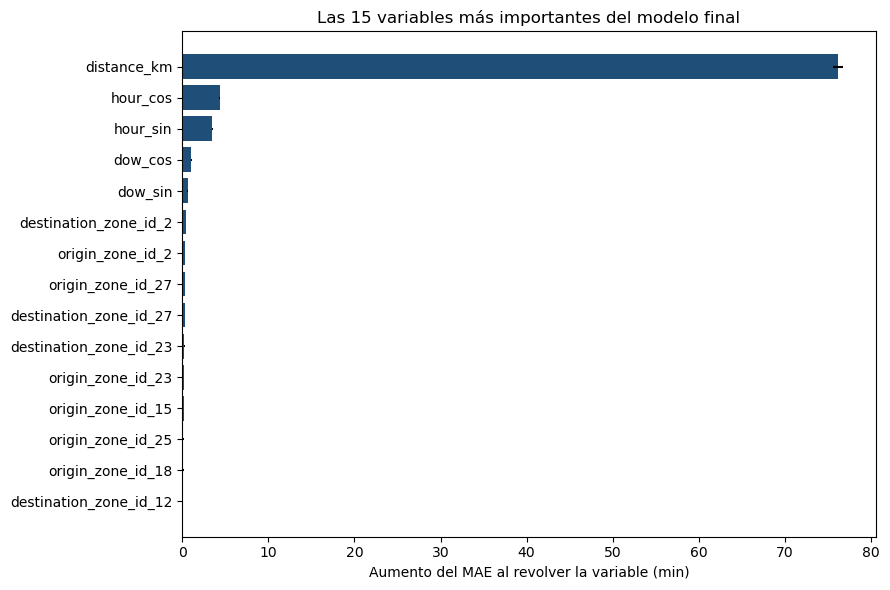

,aumento_MAE_min,desv_min
distance_km,76.150,0.555
hour_cos,4.347,0.050
hour_sin,3.495,0.032
dow_cos,1.051,0.049
dow_sin,0.637,0.047
destination_zone_id_2,0.415,0.012
origin_zone_id_2,0.335,0.025
origin_zone_id_27,0.293,0.007
destination_zone_id_27,0.277,0.010
destination_zone_id_23,0.259,0.018


In [55]:
from sklearn.inspection import permutation_importance

muestra = X_test.sample(3_000, random_state=SEMILLA)
inicio = time.perf_counter()
perm = permutation_importance(modelo_final, muestra, y_test.loc[muestra.index],
                              scoring="neg_mean_absolute_error", n_repeats=5,
                              random_state=SEMILLA, n_jobs=1)
print(f"Tiempo: {time.perf_counter() - inicio:.0f} s")

importancia = pd.DataFrame({
    "aumento_MAE_min": perm.importances_mean / 60,
    "desv_min": perm.importances_std / 60,
}, index=muestra.columns).sort_values("aumento_MAE_min", ascending=False)

top = importancia.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["aumento_MAE_min"], xerr=top["desv_min"], color="#1f4e79")
ax.set_xlabel("Aumento del MAE al revolver la variable (min)")
ax.set_title("Las 15 variables más importantes del modelo final")
plt.tight_layout()
plt.show()

importancia.head(15).round(3)

> **Por escribir:** ¿qué variables dominan? Se espera que la distancia sea la principal; lo interesante es qué sigue (¿la hora, ciertas zonas de destino?) y si eso coincide con lo que sabemos de la operación de Feraltar.

### 10.6 Error por hora del día

Conecta con la retroalimentación del Avance 3: si la duración cambia por el tráfico según la hora, el modelo podría equivocarse más en ciertos horarios. La hora se recupera de las variables cíclicas `hour_sin` y `hour_cos`.

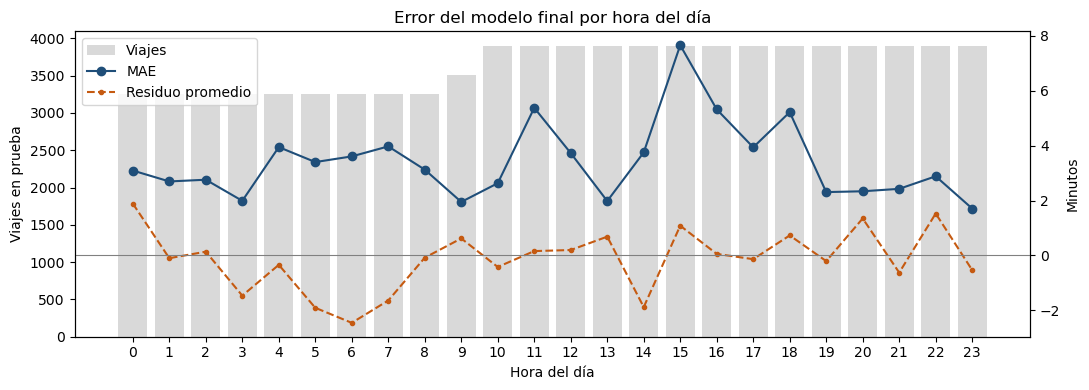

,MAE_min,residuo_medio_min,viajes
hora,,,
0,3.09,1.89,3250
1,2.70,-0.10,3250
2,2.76,0.14,3250
3,1.99,-1.46,3250
4,3.95,-0.34,3250
5,3.40,-1.91,3250
6,3.61,-2.46,3250
7,3.97,-1.64,3250
8,3.13,-0.08,3250


In [58]:
hora = (np.round(np.arctan2(X_test["hour_sin"], X_test["hour_cos"]) / (2 * np.pi) * 24) % 24).astype(int)
por_hora = pd.DataFrame({"hora": hora.values, "error": np.abs(residuo), "residuo": residuo})
resumen_hora = por_hora.groupby("hora").agg(MAE_min=("error", "mean"),
                                            residuo_medio_min=("residuo", "mean"),
                                            viajes=("error", "size"))

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(resumen_hora.index, resumen_hora["viajes"], color="#d9d9d9", label="Viajes")
ax1.set_xlabel("Hora del día")
ax1.set_ylabel("Viajes en prueba")
ax1.set_xticks(range(24))
ax2 = ax1.twinx()
ax2.plot(resumen_hora.index, resumen_hora["MAE_min"], color="#1f4e79", marker="o", label="MAE")
ax2.plot(resumen_hora.index, resumen_hora["residuo_medio_min"], color="#c55a11", marker=".",
         linestyle="--", label="Residuo promedio")
ax2.axhline(0, color="gray", linewidth=0.8)
ax2.set_ylabel("Minutos")
lineas1, etiquetas1 = ax1.get_legend_handles_labels()
lineas2, etiquetas2 = ax2.get_legend_handles_labels()
ax2.legend(lineas1 + lineas2, etiquetas1 + etiquetas2, loc="upper left")
ax1.set_title("Error del modelo final por hora del día")
plt.tight_layout()
plt.show()

resumen_hora.round(2)

> **Por escribir:** ¿hay horas con más error o con residuo sistemáticamente positivo (el modelo se queda corto en horas pico)? Si sí, es un argumento para agregar tráfico externo, como sugirió la retroalimentación.

## 11. Conclusiones

> **Por escribir.** Puntos a cubrir:
>
> 1. ¿Los ensambles mejoraron significativamente a la MLP ajustada? ¿Cuánto en minutos y en %? ¿Y respecto al baseline de 7.93 min?
> 2. Homogéneos contra heterogéneos: ¿cuál estrategia funcionó mejor en este problema y por qué?
> 3. Modelo final elegido y su principal trade-off.
> 4. Lo que dicen los gráficos sobre la calidad de las predicciones en datos no vistos (sesgo, viajes largos, horas con más error).
> 5. Siguientes pasos: datos externos de tráfico y clima (sección 1), validación con viajes reales del piloto GPS y despliegue del modelo en el panel.

## 12. Bibliografía

- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189-1232.
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Singh, A. (2023, julio 14). *Comprehensive Guide to Ensemble Learning (with Python codes)*. Analytics Vidhya. https://www.analyticsvidhya.com/blog/2018/06/comprehensive-guide-for-ensemble-models/
- VanderPlas, J. (2022). *Python Data Science Handbook* (2nd ed.). O'Reilly Media.
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241-259.

## 13. Declaración sobre el uso de herramientas de inteligencia artificial

**Herramienta utilizada:** Claude (Anthropic), asistente conversacional.

### Uso de inteligencia artificial

Usamos Claude para:

- Proponer la estructura del notebook y adaptar la función `registrar` del Avance 4 para guardar modelos y predicciones.
- Ayudarnos a investigar y redactar la respuesta a la retroalimentación del Avance 3 (APIs de tráfico y clima).

Revisamos, ejecutamos y validamos el código y los resultados. Las interpretaciones, la elección del modelo final y las conclusiones son del equipo.


### Contribución de cada integrante

| Integrante | Contribución |
|---|---|
| Alejandra Guadalupe Larrañaga Altamirano | Estructura del notebook, respuesta a la retroalimentación, ensambles heterogéneos (voting y stacking), tabla comparativa y elección del modelo final |
| Mario Alberto Guillén | *Por escribir* |
| Andrea Kimberly Fray Tamayo | *Por escribir* |

### Decisiones del equipo y alternativas descartadas

1. **Usar `HistGradientBoostingRegressor` para el boosting.** *Alternativa descartada:* `GradientBoostingRegressor` clásico, decenas de veces más lento con 350 mil viajes, o XGBoost/LightGBM, que agregan dependencias al proyecto con un desempeño similar.
2. **Usar Ridge como metamodelo del stacking.** *Alternativa descartada:* un metamodelo no lineal (por ejemplo, otro árbol), que con solo tres predicciones muy correlacionadas como entrada tendería a sobreajustar y haría menos claro el peso de cada modelo base.
3. **Limitar la profundidad y el muestreo de Random Forest y Extra Trees.** *Alternativa descartada:* árboles completos, que ocuparían varios GB de memoria y serían inviables para desplegar en el servidor de la plataforma.